# Quantum Foruier Transform (QFT)

QFT is a unitary quantum operation, not a measurement operation. It transforms the amplitudes and phases of a quantum state. Measurement is a separate process used to extract information from the resulting state.

The Quantum Fourier Transform (QFT) is the quantum analogue of the classical Discrete Fourier Transform (DFT).

It transforms a quantum state expressed in the computational basis into a state expressed in the Fourier basis.

For an $N$-dimensional quantum state:
$$
|\psi\rangle=\sum_{x=0}^{N-1}a_x|x\rangle
$$

the QFT produces:
$$
|\psi'\rangle=
\sum_{y=0}^{N-1}b_y|y\rangle
$$

where:
$$
b_y=\frac{1}{\sqrt N}
\sum_{x=0}^{N-1}a_xe^{2\pi ixy/N}
$$

## Comparing with classical DFT

The classical DFT is:
$$
X[k]=\sum_{n=0}^{N-1}x[n]e^{-2\pi i kn/N}
$$

The QFT is:
$$
|x\rangle\longrightarrow
\frac{1}{\sqrt N}
\sum_{y=0}^{N-1}e^{2\pi ixy/N}|y\rangle
$$

Notice the relationship:
- Classical DFT transforms a sequence of numbers.
- QFT transforms the amplitudes of a quantum state.
- Classical DFT is a mathematical transformation.
- QFT is a unitary operation that can be implemented as a quantum circuit.
The sign convention differs in some definitions. Here, we'll consistently use the positive exponential convention for QFT.


Importance:

The important idea is that quantum systems can encode information in relative phases. QFT provides a way to transform those phase relationships into amplitudes that can reveal useful information through measurement.

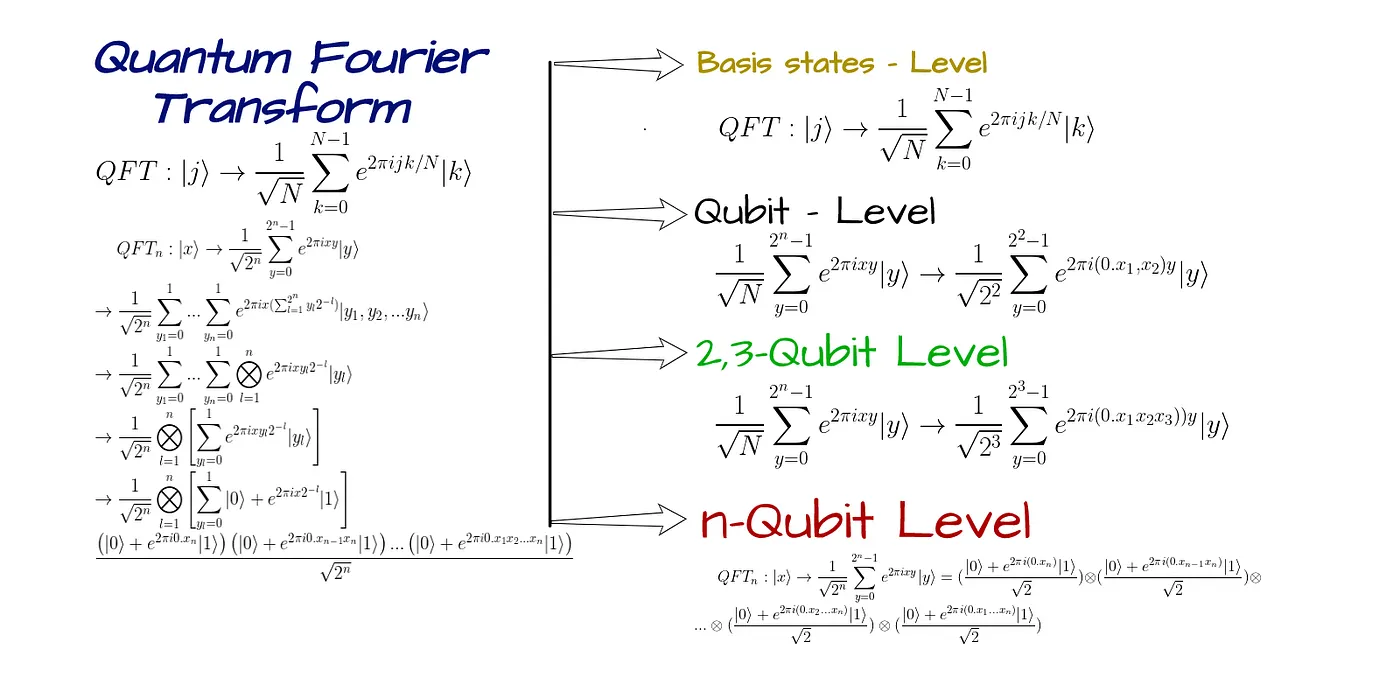

## Step by Step 

In [1]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.visualization import plot_bloch_multivector
from qiskit.quantum_info import Statevector

from numpy import pi

In [2]:
# Preparation for 3 qubit circuit

qr = QuantumRegister(3)
cr = ClassicalRegister(3)
qc = QuantumCircuit(qr, cr)

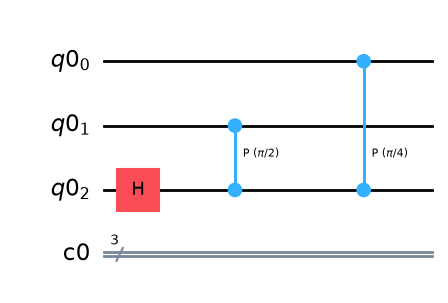

In [3]:
qc.h(2)  # Hadamard gate on qubit 2
qc.cp(pi / 2, 1, 2)  # Controlled-phase gate from qubit 1 to qubit 2
qc.cp(pi / 4, 0, 2)  # Controlled-phase gate from qubit 0 to qubit 2
qc.draw(output="mpl")

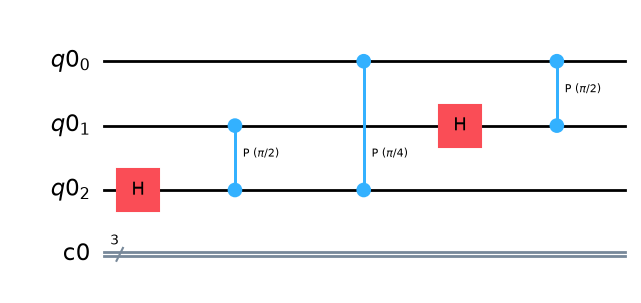

In [4]:
qc.h(1)  # Hadamard gate on qubit 1
qc.cp(pi / 2, 0, 1)  # Controlled-phase gate from qubit 0 to qubit 1

qc.draw(output="mpl")

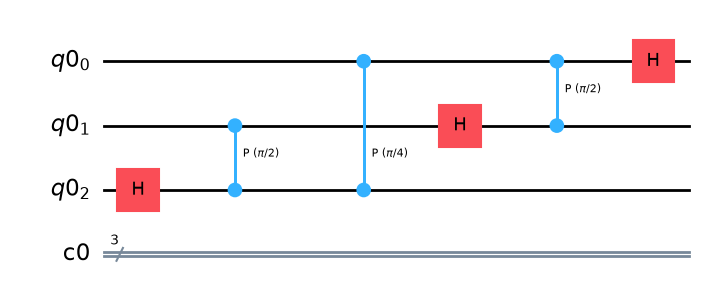

In [5]:
qc.h(0)  # Hadamard gate on qubit 0

qc.draw(output="mpl")

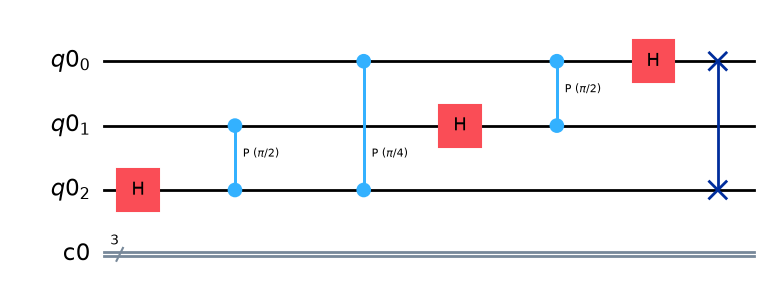

In [6]:
qc.swap(0, 2)  # Apply swap that completes the circuit

qc.draw(output="mpl")

In [7]:
# Lets try to find QFT of state |5>
#  That means 101

bin(5)

'0b101'

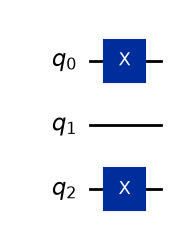

In [8]:
# Prepare 3 qubit QuantumCircuit and pass input

qc = QuantumCircuit(3)

# Change 0 to 1 for, qubit 0 and qubit 2
qc.x(0)
qc.x(2)
qc.draw("mpl")

Statevector([0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 1.+0.j, 0.+0.j,
             0.+0.j],
            dims=(2, 2, 2))


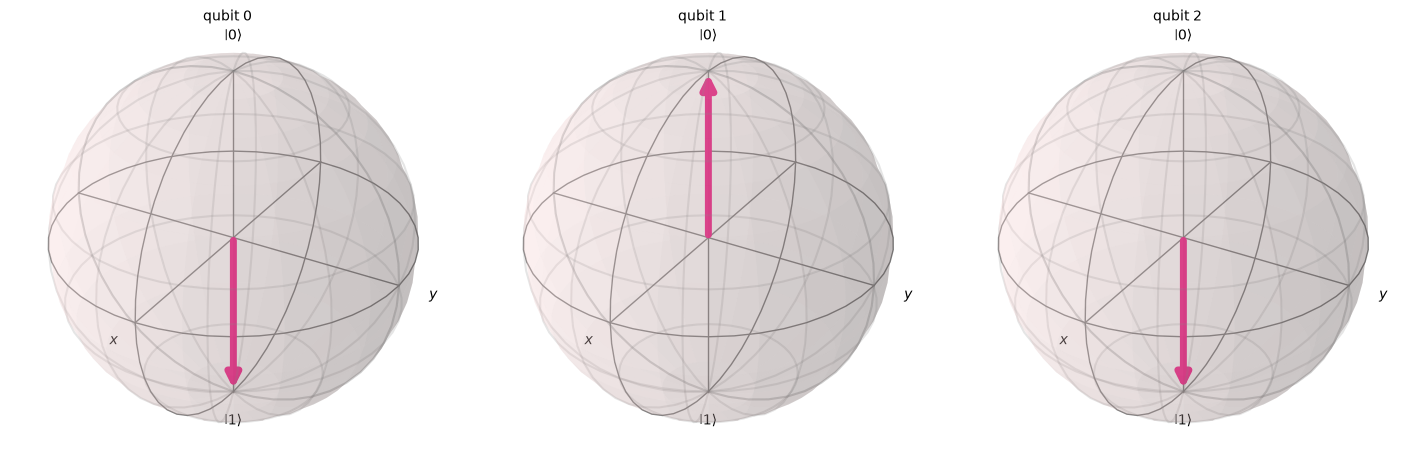

In [9]:
# Check its quantum state using Aer simulator and draw bloch sphare

statevector = Statevector(qc)
print(statevector)

plot_bloch_multivector(statevector)

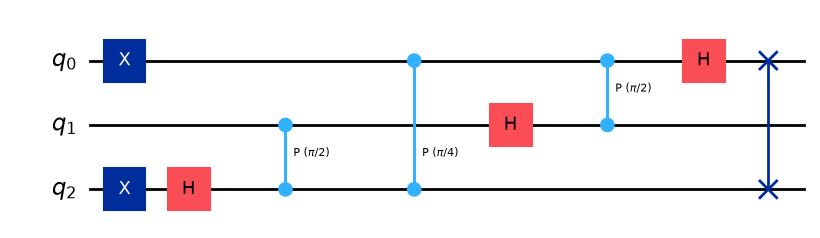

In [10]:
# Now add QFT, same steps as previous

qc.h(2)
qc.cp(pi / 2, 1, 2)
qc.cp(pi / 4, 0, 2)

qc.h(1)
qc.cp(pi / 2, 0, 1)

qc.h(0)

qc.swap(0, 2)

qc.draw(output="mpl")

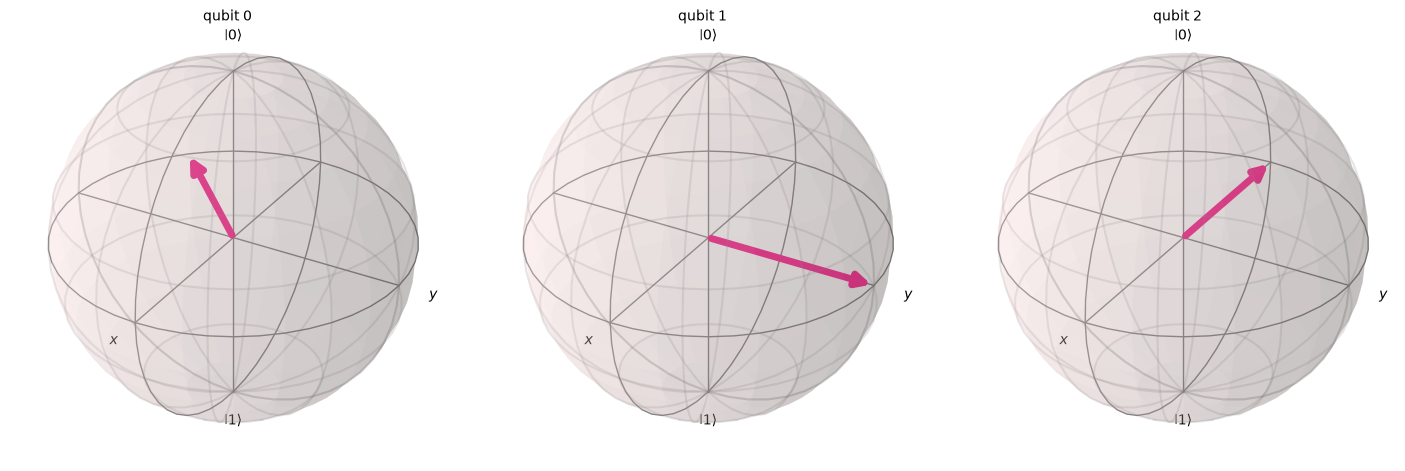

In [11]:
# Now check the state vectors

statevector = Statevector(qc)
plot_bloch_multivector(statevector)

We can see out QFT function has worked correctly. Qubit 0 has been rotated by $5/8$ of a full turn, qubit 1 by $10/8$ full turns (equivalent to $1/4$ of a full turn), and qubit 2 by $20/8$ full turns (equivalent to $1/2$ of a full turn).

## Combinational Realization

In [12]:
# Import packages

import numpy as np
from qiskit import QuantumCircuit

In [13]:
def qft(n: int, do_swap: bool = True, labeled: bool = True) -> QuantumCircuit:
    """
    n-qubit quantum fourier circuit or gate
    """

    if n < 1:
        raise ValueError("n must be at least 1")

    qc = QuantumCircuit(n, name=f"QFT_{n}")

    # Apply Hadamard and controlled phase gate
    for target in range(n-1, -1, -1):
        qc.h(target)

        for control in range(target-1, -1, -1):
            angle = np.pi / (2 ** (target-control))
            qc.cp(angle, control, target)

        if labeled:
            qc.barrier(label=f"q{target}")
        else:
            qc.barrier()

    # Reverse qubit ordering
    if do_swap:
        for i in range(n//2):
            qc.swap(i, n-i-1)
        if labeled and n > 1:
            qc.barrier(label="swap")
        elif n > 1:
            qc.barrier()

    return qc

In [14]:
qc_3 = qft(3)
print(qc_3.draw(output="text"))

                             q2                q1 ┌───┐ q0     swap 
q_0: ───────────────■────────░────────■────────░──┤ H ├─░───X───░───
                    │        ░  ┌───┐ │P(π/2)  ░  └───┘ ░   │   ░   
q_1: ──────■────────┼────────░──┤ H ├─■────────░────────░───┼───░───
     ┌───┐ │P(π/2)  │P(π/4)  ░  └───┘          ░        ░   │   ░   
q_2: ┤ H ├─■────────■────────░─────────────────░────────░───X───░───
     └───┘                   ░                 ░        ░       ░   


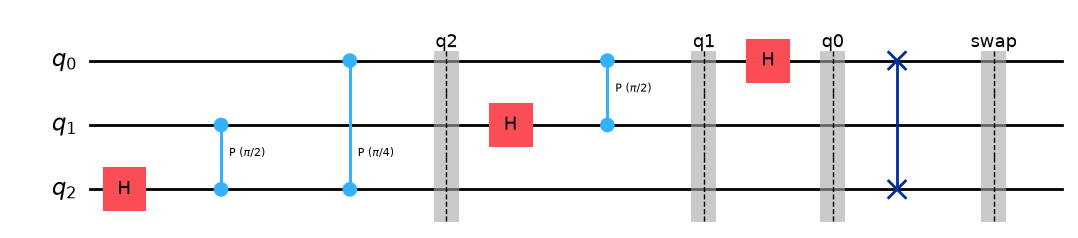

In [15]:
qc_3.draw(output="mpl")

In [16]:
# Prepare an input state and apply the circuit
# Let's use the integer x=1, whose 3-qubit representation is |001>.

from qiskit.quantum_info import Statevector
import matplotlib.pyplot as plt

In [17]:
input_qc = QuantumCircuit(3, name="Prep_and_QFT")

input_qc.x(0)

input_qc.barrier(label="init")
input_qc.compose(qc_3, inplace=True)

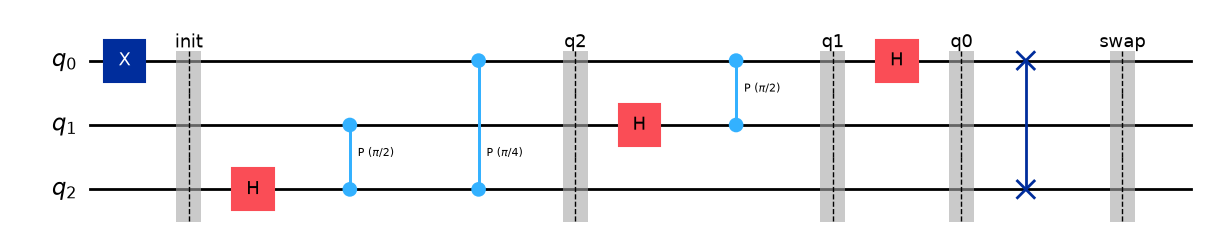

In [18]:
# Draw circuit using Matplotlib ('mpl')
input_qc.draw(output="mpl", fold=-1)

In [19]:
# Simulate exact statevector
result = Statevector.from_instruction(input_qc)
probs = result.probabilities()
phases = np.angle(result.data)  # Phase in radians in (-pi, pi]
basis_labels = [f"|{k:03b}>\n({k})" for k in range(len(probs))]

print("QFT amplitudes:")
for k, amp in enumerate(result.data):
    print(f"  |{k:03b}> (k={k}): {amp.real:+.4f} {amp.imag:+.4f}j  |  prob={probs[k]:.4f}  |  phase={np.angle(amp):+.4f} rad")

QFT amplitudes:
  |000> (k=0): +0.3536 +0.0000j  |  prob=0.1250  |  phase=+0.0000 rad
  |001> (k=1): +0.2500 +0.2500j  |  prob=0.1250  |  phase=+0.7854 rad
  |010> (k=2): +0.0000 +0.3536j  |  prob=0.1250  |  phase=+1.5708 rad
  |011> (k=3): -0.2500 +0.2500j  |  prob=0.1250  |  phase=+2.3562 rad
  |100> (k=4): -0.3536 +0.0000j  |  prob=0.1250  |  phase=+3.1416 rad
  |101> (k=5): -0.2500 -0.2500j  |  prob=0.1250  |  phase=-2.3562 rad
  |110> (k=6): -0.0000 -0.3536j  |  prob=0.1250  |  phase=-1.5708 rad
  |111> (k=7): +0.2500 -0.2500j  |  prob=0.1250  |  phase=-0.7854 rad


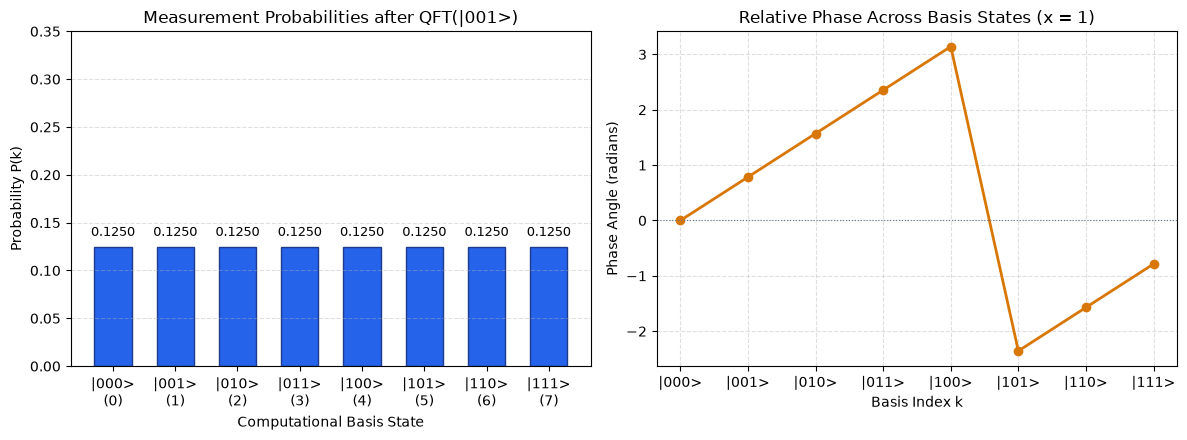

In [20]:
# Bar chart of measurement probabilities & phase progression
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

bars = ax1.bar(basis_labels, probs, color="#2563eb", edgecolor="#1e3a8a", width=0.6)
ax1.set_title("Measurement Probabilities after QFT(|001>)")
ax1.set_xlabel("Computational Basis State")
ax1.set_ylabel("Probability P(k)")
ax1.set_ylim(0, max(0.35, probs.max() * 1.3))
ax1.grid(axis="y", linestyle="--", alpha=0.4)

for bar, p in zip(bars, probs):
    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.008,
        f"{p:.4f}",
        ha="center",
        va="bottom",
        fontsize=9,
    )

ax2.plot(range(len(phases)), phases, marker="o", linestyle="-", color="#d97706", linewidth=2)
ax2.axhline(0, color="#64748b", linewidth=0.8, linestyle=":")
ax2.set_title("Relative Phase Across Basis States (x = 1)")
ax2.set_xlabel("Basis Index k")
ax2.set_ylabel("Phase Angle (radians)")
ax2.set_xticks(range(len(phases)))
ax2.set_xticklabels([f"|{k:03b}>" for k in range(len(phases))])
ax2.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

QFT amplitudes:
  |0> (k=0): +0.7071 +0.0000j  |  prob=0.5000  |  phase=+0.0000 rad
  |1> (k=1): -0.7071 +0.0000j  |  prob=0.5000  |  phase=+3.1416 rad


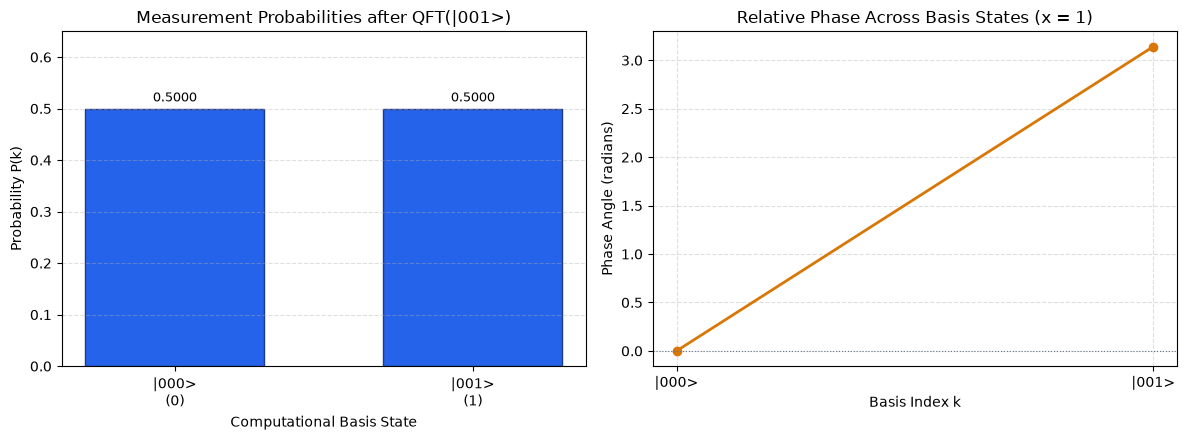

In [21]:
# For single qubit

input_qc = QuantumCircuit(1, name="Prep_and_QFT")

input_qc.x(0)

input_qc.barrier(label="init")
input_qc.compose(qft(1), inplace=True)

input_qc.draw(output="mpl", fold=-1)

result = Statevector.from_instruction(input_qc)
probs = result.probabilities()
phases = np.angle(result.data) 
basis_labels = [f"|{k:03b}>\n({k})" for k in range(len(probs))]

print("QFT amplitudes:")
for k, amp in enumerate(result.data):
    print(f"  |{k:01b}> (k={k}): {amp.real:+.4f} {amp.imag:+.4f}j  |  prob={probs[k]:.4f}  |  phase={np.angle(amp):+.4f} rad")


# Bar chart of measurement probabilities & phase progression
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

bars = ax1.bar(basis_labels, probs, color="#2563eb", edgecolor="#1e3a8a", width=0.6)
ax1.set_title("Measurement Probabilities after QFT(|001>)")
ax1.set_xlabel("Computational Basis State")
ax1.set_ylabel("Probability P(k)")
ax1.set_ylim(0, max(0.35, probs.max() * 1.3))
ax1.grid(axis="y", linestyle="--", alpha=0.4)

for bar, p in zip(bars, probs):
    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.008,
        f"{p:.4f}",
        ha="center",
        va="bottom",
        fontsize=9,
    )

ax2.plot(range(len(phases)), phases, marker="o", linestyle="-", color="#d97706", linewidth=2)
ax2.axhline(0, color="#64748b", linewidth=0.8, linestyle=":")
ax2.set_title("Relative Phase Across Basis States (x = 1)")
ax2.set_xlabel("Basis Index k")
ax2.set_ylabel("Phase Angle (radians)")
ax2.set_xticks(range(len(phases)))
ax2.set_xticklabels([f"|{k:03b}>" for k in range(len(phases))])
ax2.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

QFT amplitudes:
  |00> (k=0): +0.5000 +0.0000j  |  prob=0.2500  |  phase=+0.0000 rad
  |01> (k=1): +0.0000 +0.5000j  |  prob=0.2500  |  phase=+1.5708 rad
  |10> (k=2): -0.5000 +0.0000j  |  prob=0.2500  |  phase=+3.1416 rad
  |11> (k=3): -0.0000 -0.5000j  |  prob=0.2500  |  phase=-1.5708 rad


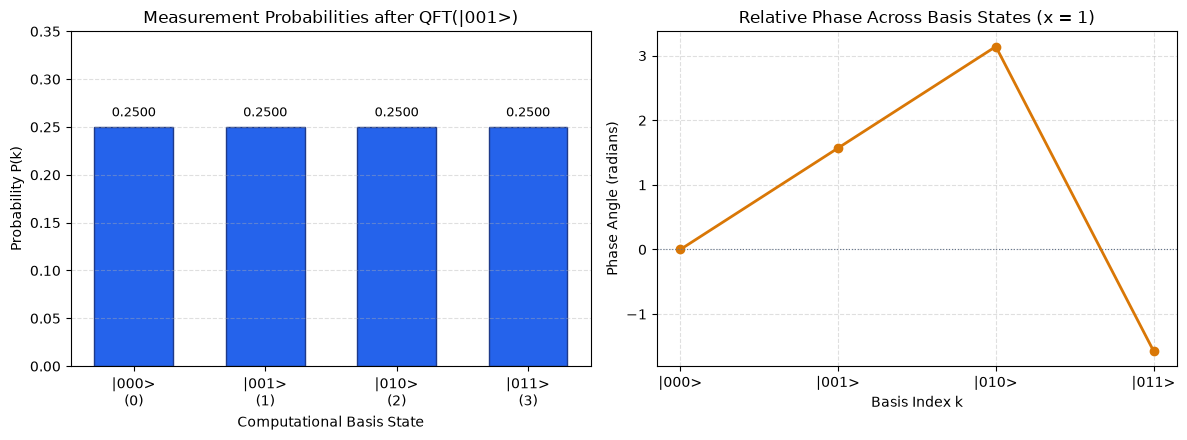

In [22]:
# For two qubit

input_qc = QuantumCircuit(2, name="Prep_and_QFT")

input_qc.x(0)

input_qc.barrier(label="init")
input_qc.compose(qft(2), inplace=True)

input_qc.draw(output="mpl", fold=-1)

result = Statevector.from_instruction(input_qc)
probs = result.probabilities()
phases = np.angle(result.data) 
basis_labels = [f"|{k:03b}>\n({k})" for k in range(len(probs))]

print("QFT amplitudes:")
for k, amp in enumerate(result.data):
    print(f"  |{k:02b}> (k={k}): {amp.real:+.4f} {amp.imag:+.4f}j  |  prob={probs[k]:.4f}  |  phase={np.angle(amp):+.4f} rad")


# Bar chart of measurement probabilities & phase progression
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

bars = ax1.bar(basis_labels, probs, color="#2563eb", edgecolor="#1e3a8a", width=0.6)
ax1.set_title("Measurement Probabilities after QFT(|001>)")
ax1.set_xlabel("Computational Basis State")
ax1.set_ylabel("Probability P(k)")
ax1.set_ylim(0, max(0.35, probs.max() * 1.3))
ax1.grid(axis="y", linestyle="--", alpha=0.4)

for bar, p in zip(bars, probs):
    ax1.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.008,
        f"{p:.4f}",
        ha="center",
        va="bottom",
        fontsize=9,
    )

ax2.plot(range(len(phases)), phases, marker="o", linestyle="-", color="#d97706", linewidth=2)
ax2.axhline(0, color="#64748b", linewidth=0.8, linestyle=":")
ax2.set_title("Relative Phase Across Basis States (x = 1)")
ax2.set_xlabel("Basis Index k")
ax2.set_ylabel("Phase Angle (radians)")
ax2.set_xticks(range(len(phases)))
ax2.set_xticklabels([f"|{k:03b}>" for k in range(len(phases))])
ax2.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

## Using QFTGate

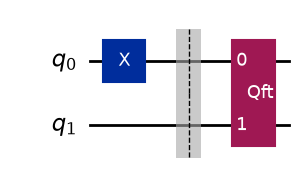

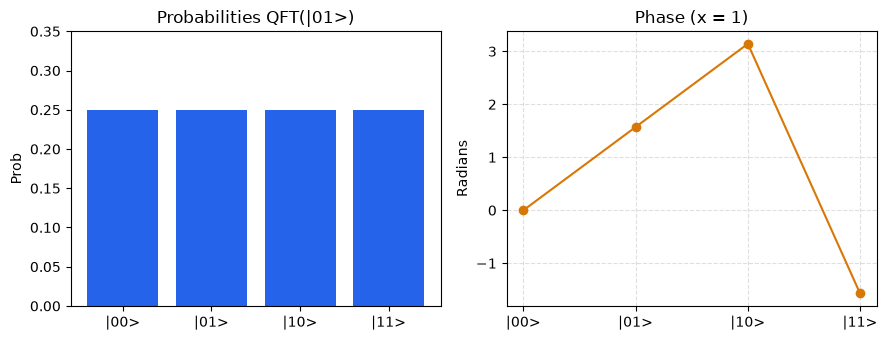

In [23]:
# Using standard QFT gate

%matplotlib inline
from qiskit.circuit.library import QFTGate


qc = QuantumCircuit(2)
qc.x(0)
qc.barrier()
qc.append(QFTGate(2), [0, 1])

qc.draw(output="mpl", fold=-1)
plt.show()

sv = Statevector(qc)
probs, phases = sv.probabilities(), np.angle(sv.data)
labels = [f"|{k:02b}>" for k in range(4)]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.5))
ax1.bar(labels, probs, color="#2563eb")
ax1.set(title="Probabilities QFT(|01>)", ylabel="Prob", ylim=(0, 0.35))

ax2.plot(labels, phases, marker="o", color="#d97706")
ax2.set(title="Phase (x = 1)", ylabel="Radians")
ax2.grid(True, ls="--", alpha=0.4)

plt.tight_layout()
plt.show()

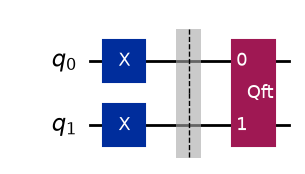

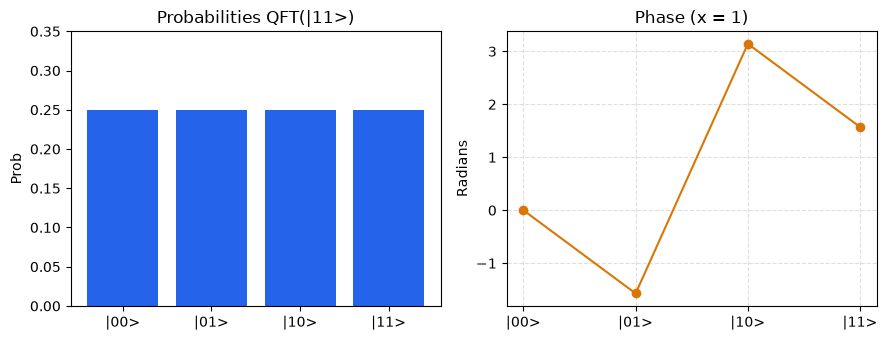

In [24]:
# Using standard QFT gate

qc = QuantumCircuit(2)
qc.x([0, 1])
qc.barrier()
qc.append(QFTGate(2), [0, 1])

qc.draw(output="mpl", fold=-1)
plt.show()

sv = Statevector(qc)
probs, phases = sv.probabilities(), np.angle(sv.data)
labels = [f"|{k:02b}>" for k in range(4)]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.5))
ax1.bar(labels, probs, color="#2563eb")
ax1.set(title="Probabilities QFT(|11>)", ylabel="Prob", ylim=(0, 0.35))

ax2.plot(labels, phases, marker="o", color="#d97706")
ax2.set(title="Phase (x = 1)", ylabel="Radians")
ax2.grid(True, ls="--", alpha=0.4)

plt.tight_layout()
plt.show()